In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- Konfigurasi tampilan grafik

In [43]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

- Memuat dataset

In [44]:
df = pd.read_csv('./src/data/clean_reviews.csv')

1. Pengecekan Missing Value

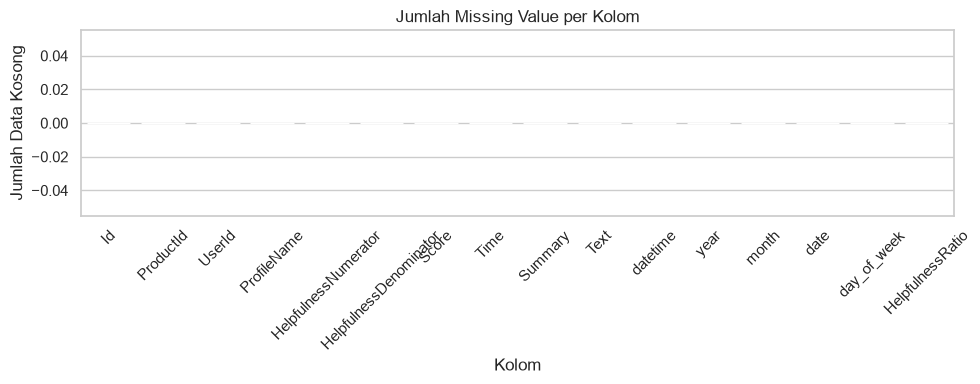

In [45]:
# Ubah hasil sum() dari Series menjadi DataFrame
missing_df = df.isnull().sum().reset_index()
missing_df.columns = ['Kolom', 'Jumlah']

plt.figure(figsize=(10, 4))
sns.barplot(data=missing_df, x='Kolom', y='Jumlah', color='#3498db')
plt.title('Jumlah Missing Value per Kolom')
plt.ylabel('Jumlah Data Kosong')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Pengecekan Duplikasi Baris Data

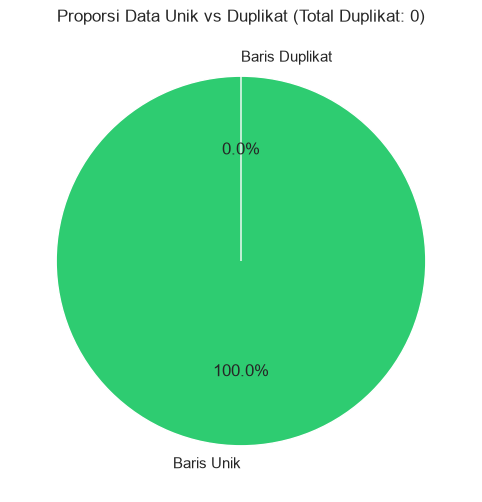

In [46]:
duplicate_count = df.duplicated().sum()
unique_count = len(df) - duplicate_count

plt.figure(figsize=(6, 6))
plt.pie(
    [unique_count, duplicate_count],
    labels=['Baris Unik', 'Baris Duplikat'],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    explode=(0, 0.1) if duplicate_count > 0 else (0, 0),
    startangle=90
)
plt.title(
    f'Proporsi Data Unik vs Duplikat (Total Duplikat: {duplicate_count})')
plt.show()

3. Deteksi dan Visualisasi Outlier

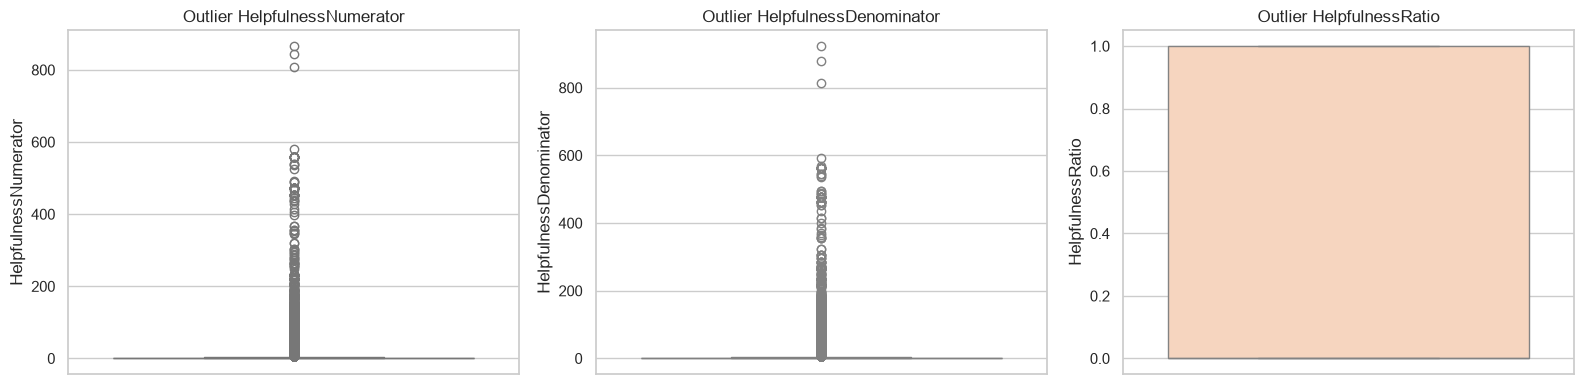

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Gunakan data=df dan passing nama kolom sebagai string
sns.boxplot(data=df, y='HelpfulnessNumerator', ax=axes[0], color='#a8e6cf')
axes[0].set_title('Outlier HelpfulnessNumerator')

sns.boxplot(data=df, y='HelpfulnessDenominator', ax=axes[1], color='#dcedc1')
axes[1].set_title('Outlier HelpfulnessDenominator')

sns.boxplot(data=df, y='HelpfulnessRatio', ax=axes[2], color='#ffd3b6')
axes[2].set_title('Outlier HelpfulnessRatio')

plt.tight_layout()
plt.show()

4. Pengecekan Konsistensi Format Kategori

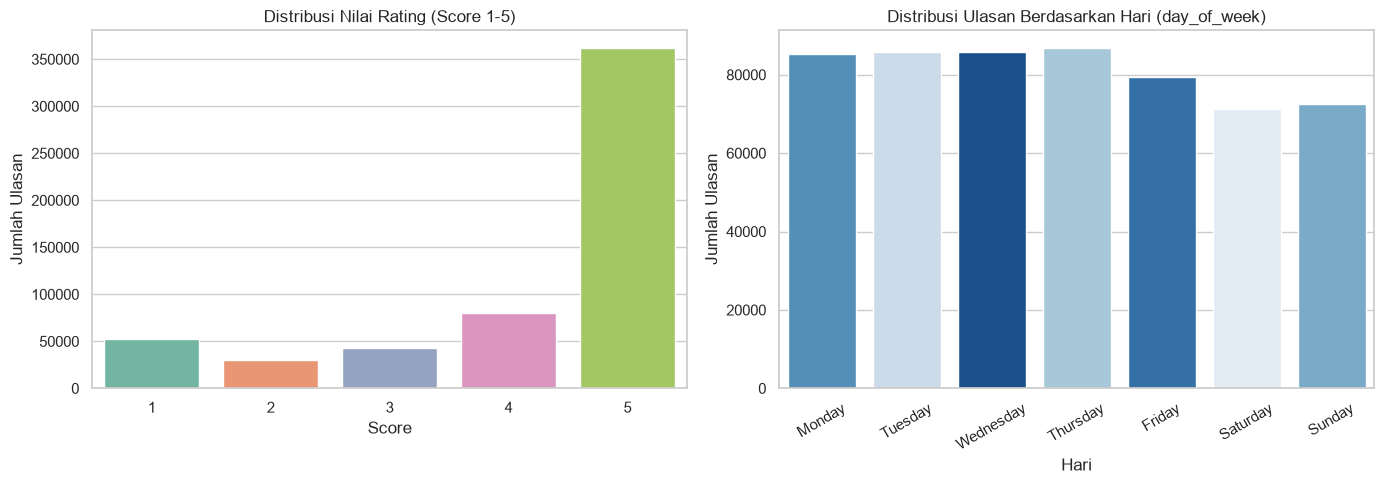

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi Rating (Score 1-5)
sns.countplot(
    data=df, x='Score', hue='Score', palette='Set2', legend=False, ax=axes[0]
)
axes[0].set_title('Distribusi Nilai Rating (Score 1-5)')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Jumlah Ulasan')

# Distribusi Hari (day_of_week)
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
sns.countplot(
    data=df,
    x='day_of_week',
    hue='day_of_week',
    order=days_order,
    palette='Blues_r',
    legend=False,
    ax=axes[1],
)
axes[1].set_title('Distribusi Ulasan Berdasarkan Hari (day_of_week)')
axes[1].set_xlabel('Hari')
axes[1].set_ylabel('Jumlah Ulasan')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

5. Visualisasi Encoding Kolom Kategorikal & Korelasi Fitur

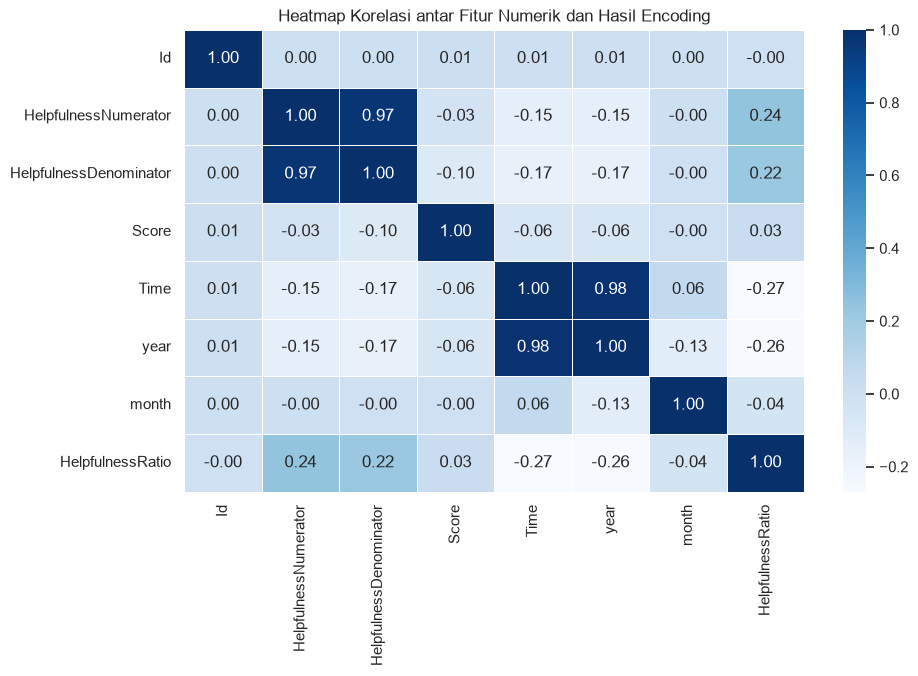

In [49]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(10, 6))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True,
            fmt=".2f", cmap='Blues', linewidths=0.5)
plt.title('Heatmap Korelasi antar Fitur Numerik dan Hasil Encoding')
plt.show()